# 🎧 DSP Final Project Guide: คู่มือทำความเข้าใจระบบตัดเสียงสะท้อน (AEC)
### สำหรับเพื่อนร่วมทีมโปรเจกต์ DSP
สมุดเล่มนี้เขียนขึ้นเพื่ออธิบาย **"หัวใจของปัญหา"** และ **"แนวทางการแก้ปัญหา"** ด้วยตัวอย่าง Sine Wave แบบง่ายๆ ให้เห็นภาพชัดเจนที่สุด ก่อนจะนำไปใช้กับสัญญาณเสียงคนพูดจริงครับ!


---
## ⚙️ ส่วนที่ 0: ตั้งค่าและโหลดฟังก์ชันพื้นฐานจากแล็บ
รันเซลล์นี้ก่อนเพื่อดึงฟังก์ชันคำนวณและตั้งค่าฟอนต์ภาษาไทยสำหรับกราฟครับ


In [2]:
import sys
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy import signal

# ตั้งค่าฟอนต์ภาษาไทยสำหรับพล็อตกราฟ
matplotlib.rcParams["font.family"] = ["Tahoma", "Leelawadee UI", "DejaVu Sans"]
matplotlib.rcParams["axes.unicode_minus"] = False

# ชี้พาธไปยังรากของโปรเจกต์
PROJECT_ROOT = Path(r"C:\Users\khaok\69-1\DSP\FinalProject")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# ฟังก์ชันพื้นฐานจากแล็บ
def time_axis(fs, duration):
    T = 1 / fs
    return np.arange(0, duration, T)

def generate_sine(f, t, A=1, p=0):
    return A * np.sin(2 * np.pi * f * t + p)

def spectrum(x, NFFT=-1):
    if NFFT == -1:
        NFFT = len(x)
    X = np.fft.fft(x, NFFT)
    N = len(X)
    X = X[:N // 2]
    mag = np.abs(X) * 2 / N
    freq = np.arange(len(mag)) * fs / N
    return freq, mag

# ดึงฟังก์ชันจำลองห้องสะท้อนเสียงจากโฟลเดอร์ src/
from src.simulation.room_simulator import (
    create_fixed_room_ir,
    simulate_static_room_echo,
)
print("✅ ตั้งค่าระบบและนำเข้าฟังก์ชันสำเร็จพร้อมใช้งาน!")


✅ ตั้งค่าระบบและนำเข้าฟังก์ชันสำเร็จพร้อมใช้งาน!


---
## 🌊 ส่วนที่ 1: สร้าง 2 สัญญาณเปรียบเทียบใน Time Domain (Original vs Echo)

สมมติสถานการณ์:
1. **`x_orig` (เสียงต้นฉบับจากลำโพง):** มี 3 ความถี่ผสมกันคือ **120 Hz, 210 Hz, 500 Hz**
2. **`x_echo` (เสียงที่ไมค์ดูดเข้ามา):** คือเสียงต้นฉบับที่สะท้อนมา (ความดังลดลงเหลือ 60%) แต่ **มีเสียงแทรกความถี่ 325 Hz แอบโผล่มาเฉพาะในไมค์!** (เช่น เสียงคนพูดหน้าไมค์)


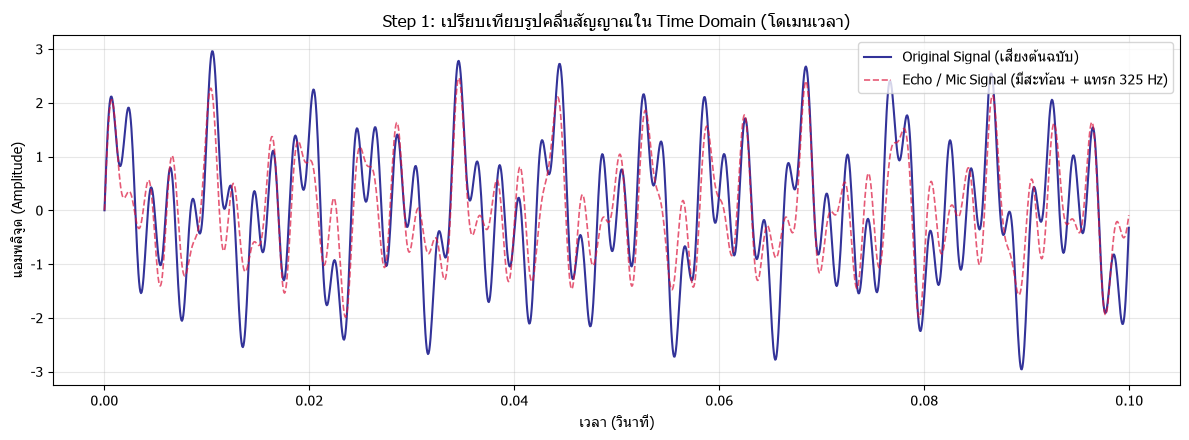

In [3]:
fs = 16000           
duration = 0.1
t = time_axis(fs, duration)

# 1. เสียงต้นฉบับ (Original): ผสม 3 ความถี่ (120, 210, 500 Hz)
x1 = generate_sine(120, t, A=1.0)
x2 = generate_sine(210, t, A=1.0)
x4 = generate_sine(500, t, A=1.0)
x_orig = x1 + x2 + x4

# 2. เสียงสะท้อน (Echo): นำเสียงต้นฉบับมาเบาลง + มีเสียงแทรก 325 Hz โผล่มาเฉพาะในไมค์!
x3_interference = generate_sine(325, t, A=0.8)
x_echo = 0.6 * x_orig + x3_interference

# 3. พล็อตกราฟเปรียบเทียบในโดเมนเวลา (Time Domain)
plt.figure(figsize=(12, 4.5))
plt.plot(t, x_orig, label="Original Signal (เสียงต้นฉบับ)", color="navy", lw=1.5, alpha=0.8)
plt.plot(t, x_echo, label="Echo / Mic Signal (มีสะท้อน + แทรก 325 Hz)", color="crimson", lw=1.2, linestyle="--", alpha=0.7)
plt.title("Step 1: เปรียบเทียบรูปคลื่นสัญญาณใน Time Domain (โดเมนเวลา)")
plt.xlabel("เวลา (วินาที)")
plt.ylabel("แอมพลิจูด (Amplitude)")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## 🔍 ส่วนที่ 2: พิสูจน์ Spectral Overlap (ทำไม Lowpass ถึงสอบตก?)

คำถามยอดฮิต: *"ทำไมเราไม่ใช้ Lowpass หรือ Bandstop Filter ง่ายๆ มากรองเสียงสะท้อนออกล่ะ?"*  
**คำตอบอยู่ในกราฟสเปกตรัมข้างล่างนี้ครับ:**
* ทั้งเสียงพูดและเสียงสะท้อนมี **ความถี่ 120, 210, 500 Hz ซ้อนทับกันสนิท (Spectral Overlap)!**
* ถ้าเราใช้ Lowpass ตัดเสียงสะท้อน 500 Hz ทิ้ง ➔ เสียงพูดต้นฉบับ 500 Hz ก็จะ **โดนตัดพังไปด้วย!**
* ตัวกรองคงที่ (Fixed Filter) ไม่สามารถแยกสัญญาณ 2 ตัวที่แชร์ย่านความถี่เดียวกันได้เลย!


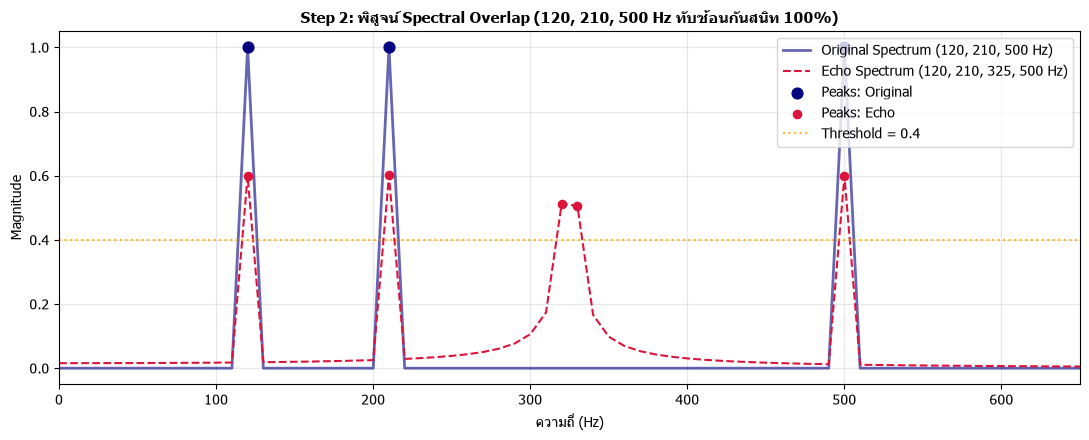

👉 ความถี่ใน Original : [120. 210. 500.] Hz
👉 ความถี่ใน Echo     : [120. 210. 320. 330. 500.] Hz
💡 สรุป: ความถี่ 120, 210, 500 Hz ซ้อนทับกันสนิท! กรองด้วย Lowpass ไม่ได้เด็ดขาด


In [4]:
# 1. แปลงสัญญาณเข้าสู่แกนความถี่ด้วย FFT
freq_orig, mag_orig = spectrum(x_orig)
freq_echo, mag_echo = spectrum(x_echo)

# 2. ตั้งเกณฑ์ Threshold หาความถี่เด่น
threshold = 0.4
peaks_orig = freq_orig[mag_orig > threshold]
peaks_echo = freq_echo[mag_echo > threshold]

# 3. พล็อตกราฟเปรียบเทียบสเปกตรัมซ้อนทับกัน (Overlay Spectrum)
plt.figure(figsize=(11, 4.5))
plt.plot(freq_orig, mag_orig, label="Original Spectrum (120, 210, 500 Hz)", color="navy", lw=2.0, alpha=0.6)
plt.plot(freq_echo, mag_echo, label="Echo Spectrum (120, 210, 325, 500 Hz)", color="crimson", lw=1.5, linestyle="--")

# ปักหมุดจุดยอดพีกของแต่ละสัญญาณ
plt.scatter(peaks_orig, mag_orig[mag_orig > threshold], color="navy", s=60, zorder=5, label="Peaks: Original")
plt.scatter(peaks_echo, mag_echo[mag_echo > threshold], color="crimson", s=35, zorder=6, label="Peaks: Echo")
plt.axhline(threshold, color="orange", linestyle=":", alpha=0.8, label=f"Threshold = {threshold}")

plt.title("Step 2: พิสูจน์ Spectral Overlap (120, 210, 500 Hz ทับซ้อนกันสนิท 100%)", fontsize=11, fontweight="bold")
plt.xlabel("ความถี่ (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 650)
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"👉 ความถี่ใน Original : {peaks_orig} Hz")
print(f"👉 ความถี่ใน Echo     : {peaks_echo} Hz")
print("💡 สรุป: ความถี่ 120, 210, 500 Hz ซ้อนทับกันสนิท! กรองด้วย Lowpass ไม่ได้เด็ดขาด")


---
## 🏠 ส่วนที่ 3: แบบจำลองห้องสะท้อนเสียงจริง (Room Impulse Response: RIR)

ในชีวิตจริง เสียงสะท้อนไม่ได้เกิดจากการคูณตัวเลขเบาลงเฉยๆ แต่เกิดจาก **คลื่นเสียงเดินทางไปชนกำแพง เพดาน โต๊ะ แล้วเด้งกลับมาหลายจังหวะ**  
เราจำลองสิ่งนี้ด้วยฟังก์ชัน **Room Impulse Response (RIR: $h[n]$)** ซึ่งมี 3 ระดับความก้อง:


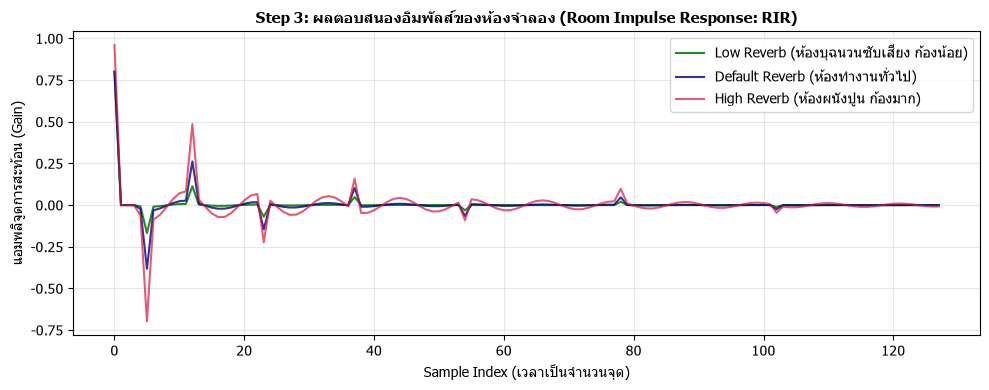

In [5]:
# จำลองผลตอบสนองของห้อง (Room Impulse Response: RIR) 3 รูปแบบ
h_low = create_fixed_room_ir(reverb_level="low", save_to_disk=False)
h_default = create_fixed_room_ir(save_to_disk=False)
h_high = create_fixed_room_ir(reverb_level="high", echo_gain=1.2, save_to_disk=False)

plt.figure(figsize=(10, 4))
plt.plot(h_low, label="Low Reverb (ห้องบุฉนวนซับเสียง ก้องน้อย)", color="forestgreen")
plt.plot(h_default, label="Default Reverb (ห้องทำงานทั่วไป)", color="navy", alpha=0.8)
plt.plot(h_high, label="High Reverb (ห้องผนังปูน ก้องมาก)", color="crimson", alpha=0.7)

plt.title("Step 3: ผลตอบสนองอิมพัลส์ของห้องจำลอง (Room Impulse Response: RIR)", fontsize=11, fontweight="bold")
plt.xlabel("Sample Index (เวลาเป็นจำนวนจุด)")
plt.ylabel("แอมพลิจูดการสะท้อน (Gain)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## 🎯 ส่วนที่ 4: เสียงสะท้อนที่ผ่านห้องจริง (Convolution: $x[n] * h[n]$)

เมื่อนำเสียงต้นฉบับ $x[n]$ มาผ่านระบบห้องที่มีการสะท้อน $h[n]$ ด้วยการ **Convolution** จะได้สัญญาณไมโครโฟนที่มีเสียงสะท้อนจริงตามหลักฟิสิกส์อะคูสติกส์:


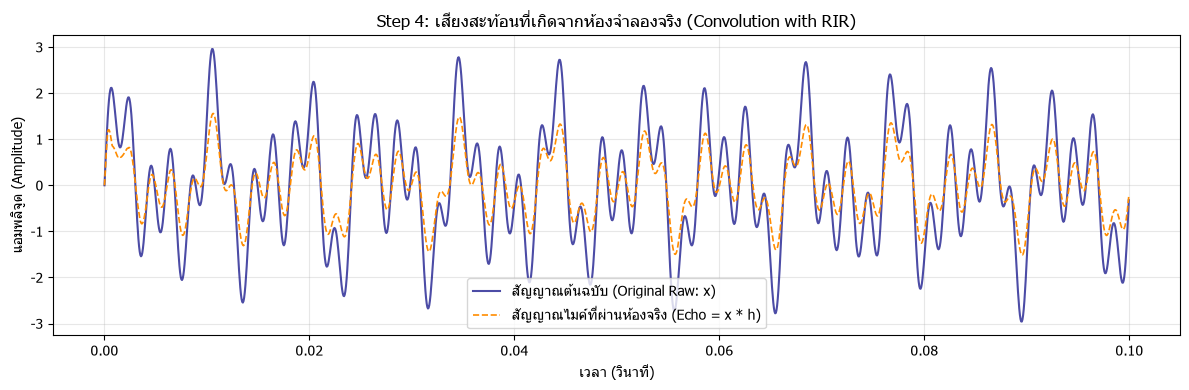

In [6]:
# จำลองการส่งเสียงต้นฉบับผ่านห้องจำลองแบบ Default
_, x_real_echo, _, _ = simulate_static_room_echo(x_orig, h_default, length_mode="trim")

plt.figure(figsize=(12, 4))
plt.plot(t, x_orig, label="สัญญาณต้นฉบับ (Original Raw: x)", color="navy", lw=1.5, alpha=0.7)
plt.plot(t, x_real_echo, label="สัญญาณไมค์ที่ผ่านห้องจริง (Echo = x * h)", color="darkorange", lw=1.2, linestyle="--")

plt.title("Step 4: เสียงสะท้อนที่เกิดจากห้องจำลองจริง (Convolution with RIR)")
plt.xlabel("เวลา (วินาที)")
plt.ylabel("แอมพลิจูด (Amplitude)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## 🗺️ แผนผังภาพรวม: ตัวกรองทั้ง 4 กลุ่มที่เรากำลังจะทำต่อในโปรเจกต์

เพื่อแก้ปัญหาเสียงสะท้อนข้างต้น ทีมเราจะแบ่งการทดลองเป็น **4 กลุ่ม (4 Pillars)** เพื่อเปรียบเทียบในรายงาน:

1. **Standard LMS (กลุ่มที่ 1):** ตัวกรองปรับตัวได้แบบพื้นฐาน ($w + \mu e x$)
2. **Normalized LMS: NLMS (กลุ่มที่ 2 - พระเอก):** ตัวกรองที่ปรับตามพลังงานเสียง ($rac{\mu}{\|x\|^2 + \epsilon}$) ปรับตัวไวและนิ่งที่สุด
3. **สิ่งที่เรียนในแล็บ (กลุ่มที่ 3):**
   * **3.1 Butterworth (W7, W9):** โชว์ว่าการตัดความถี่สอบตกเพราะ Spectral Overlap
   * **3.2 Inverse Filter (W4, W8):** ทฤษฎี Deconvolution ย้อนเสียงห้อง แต่เสี่ยงตัวกรองระเบิด
   * **3.3 FastICA / PCA (W11):** แยกเสียงแบบ Instantaneous แต่สอบตกกับห้องสะท้อน Convolutive
   * **3.4 STFT Spectral Subtraction (W12):** ลบสเปกตรัมใน Time-Frequency พอถูไถได้ดีสุด แต่เกิด Musical Noise
4. **Library Benchmark (กลุ่มที่ 4):** ดึงไลบรารีสากล (`padasip`) มาเป็นไม้บรรทัดเทียบว่าตัวที่เราเขียนมือเอง (1 & 2) ได้ผลลัพธ์มาตรฐานเทียบเท่าระดับโลก!

---
💡 **เพื่อนๆ สามารถเปิดไฟล์ `notebooks/main.ipynb` เพื่อดูโค้ดการทดลองหลักบนไฟล์เสียงคนพูดจริงได้เลยครับ!**
